# Classification du comportement du chien à partir de capteurs de mouvement

**Soutenance - notebook de présentation**

**Question** : peut-on reconnaître ce que fait un chien (couché, assis, marche, flaire, mange, halète...) à
partir de deux accéléromètres et deux gyroscopes, placés sur le dos et sur le cou ?

**Données** : 45 chiens, 62 séances, 10,6 millions de mesures à 100 Hz, comportements annotés à partir de
vidéos dans `Behavior_1`, `Behavior_2`, `Behavior_3` (comportements simultanés).

Aperçu des séries temporelles (`DogMoveData.csv`, 5 premières lignes : chien 16, test 1) :

| DogID | TestNum | t_sec | ABack_x | ABack_y | ABack_z | ANeck_x | ANeck_y | ANeck_z | GBack_x | GBack_y | GBack_z | GNeck_x | GNeck_y | GNeck_z | Task | Behavior_1 | Behavior_2 | Behavior_3 |
|:-:|:-:|:-:|--:|--:|--:|--:|--:|--:|--:|--:|--:|--:|--:|--:|:-:|:-:|:-:|:-:|
| 16 | 1 | 0.00 | 0.042 | 0.939 | -0.015 | -0.068 | -0.510 | -0.935 | -17.639 | -22.766 | 7.446 | -7.935 | 6.348 | 13.428 | - | - | - | - |
| 16 | 1 | 0.01 | 0.042 | 0.942 | -0.020 | -0.129 | -0.494 | -0.913 | -15.076 | -11.414 | 4.822 | -3.906 | 4.395 | 16.541 | - | - | - | - |
| 16 | 1 | 0.02 | 0.041 | 0.939 | -0.004 | -0.159 | -0.480 | -0.911 | -12.207 | -0.122 | 2.808 | -0.488 | -1.953 | 26.794 | - | - | - | - |
| 16 | 1 | 0.03 | 0.021 | 0.946 | 0.008 | -0.122 | -0.487 | -0.880 | -9.460 | 7.996 | 1.587 | 1.160 | -5.676 | 38.086 | - | - | - | - |
| 16 | 1 | 0.04 | -0.001 | 0.951 | 0.034 | -0.054 | -0.500 | -0.807 | -8.362 | 14.587 | -1.038 | 4.578 | 4.089 | 41.504 | - | - | - | - |

- `A...` : accéléromètre en g, `G...` : gyroscope en °/s ; `Back` = harnais (dos), `Neck` = collier (cou) ;
  une ligne toutes les 0,01 s (100 Hz).
- `-` : valeur manquante. Le début d'une séance n'est pas encore annoté (phase de synchronisation).

> **Aucun modèle n'est entraîné dans ce notebook.** Tous les entraînements (plusieurs heures au total) ont
> été faits dans les notebooks numérotés `00` à `07`, consultables à part. Ici, les résultats
> enregistrés sont relus (tableaux, figures, modèles, prédictions) et uniquement des calculs de quelques secondes sont effectués.

| Partie | Contenu | Durée orale |
|---|---|:---:|
| 1 | Intro + Exploration et préparation | 1 min 30 |
| 2 | Split train / test par chien | 0 min 30 |
| 3 | Pipeline d'entraînement et d'évaluation | 1 min 00 |
| 4 | Approche par fenêtres (modèle général) | 2 min 30 |
| 5 | Modèles spécifiques par famille | 0 min 45 |
| 6 | Comparaison avec tsfresh | 1 min 00 |
| 7 | Analyses complémentaires | 1 min 30 |
| 8 | Synthèse, discussion, ouverture | 0 min 45 + questions |

In [1]:
import sys
from pathlib import Path

# Racine du projet ajoutée au chemin d'import (le notebook est dans notebooks/)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import json, warnings
from sklearn.metrics import f1_score, roc_auc_score
from src import data, labels, modeling, evaluation, smoothing, viz, presentation as P
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")

# --- Résultats enregistrés par les notebooks 00 à 07 (lecture seule, quelques secondes) ---
dogs = data.load_dogs()
train_ids, test_ids = data.load_split()
general = modeling.load_bundle(**json.loads((cfg.TABLES_DIR / "meilleur_modele_general.json").read_text()))
classes = list(general["label_encoder"].classes_)
preds = data.load_table(cfg.PROCESSED_DIR / "predictions_test_general.parquet")   # notebook 04
proba = preds[[f"proba_{c}" for c in classes]].to_numpy()

K_LISSAGE = 21   # choisi au notebook 07 sur des prédictions hors-pli du TRAIN (jamais sur le test)
preds["pred_lisse"] = general["label_encoder"].inverse_transform(
    smoothing.smooth_proba(proba, preds, K_LISSAGE).argmax(axis=1))
print(f"Modèle général retenu : {general['model_name']} / {general['experiment']} | {len(classes)} classes | "
      f"{len(preds):,} fenêtres de test ({preds['DogID'].nunique()} chiens)")

Modèle général retenu : XGBoost / multi_echelle | 11 classes | 27,654 fenêtres de test (9 chiens)


---
## 1. Exploration et préparation des données

| Étape | Constat | Décision |
|---|---|---|
| Étiquettes `Synchronization` / `Extra_Synchronization` | servent à caler capteurs et vidéo, ce ne sont pas des comportements | **lignes conservées, label mis à manquant** : les supprimer créait des trous dans le signal, enjambés sans le savoir par les fenêtres |
| Continuité temporelle | contrôle des sauts de `t_sec` dans chaque séance | fenêtres découpées par **segment continu**, jamais à cheval sur une rupture |
| Valeurs manquantes | 38 % du temps sans `Behavior_1` (transitions, chien hors champ) | la tâche porte sur les **segments annotés** ; le non-annoté est exclu |
| Colonne `Task` | décrit l'exercice du protocole, très liée au comportement | **jamais utilisée** comme variable (indisponible en usage réel : fuite d'information) |

Séances avec au moins une rupture temporelle : 0 / 62 (plus grand écart entre deux mesures : 0.01 s)
Part du temps sans annotation (%) : {'Behavior_1': 38.2, 'Behavior_2': 71.9, 'Behavior_3': 98.1, 'Task': 24.4}


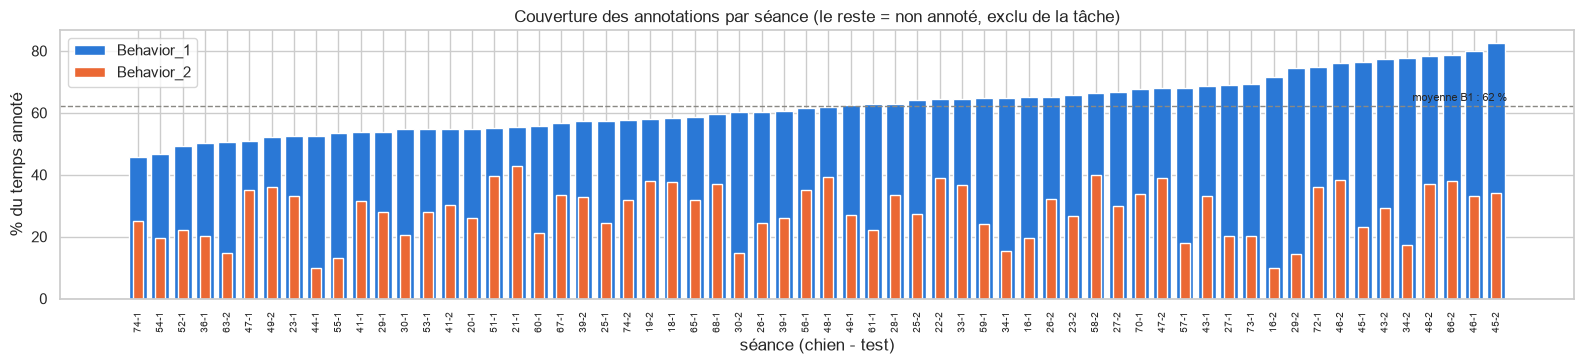

In [2]:
moves = data.load_moves()          # cache parquet du notebook 00
continuite = data.continuity_report(moves)
print(f"Séances avec au moins une rupture temporelle : {(continuite['n_ruptures'] > 0).sum()} / {len(continuite)} "
      f"(plus grand écart entre deux mesures : {continuite['plus_grand_trou_s'].max():.2f} s)")
manquants = (moves[cfg.BEHAVIOR_COLUMNS + ["Task"]].isna().mean() * 100).round(1)
print("Part du temps sans annotation (%) :", manquants.to_dict())
P.plot_couverture(data.label_coverage(moves)); plt.show()

**Lecture** : aucune rupture dans ces données, mais le contrôle est en place. La couverture de
`Behavior_1` varie de 46 % à 83 % selon la séance. `Behavior_2` est renseigné sur environ 28 % du temps :
les comportements simultanés sont fréquents.

### Profils des chiens et fréquence des comportements

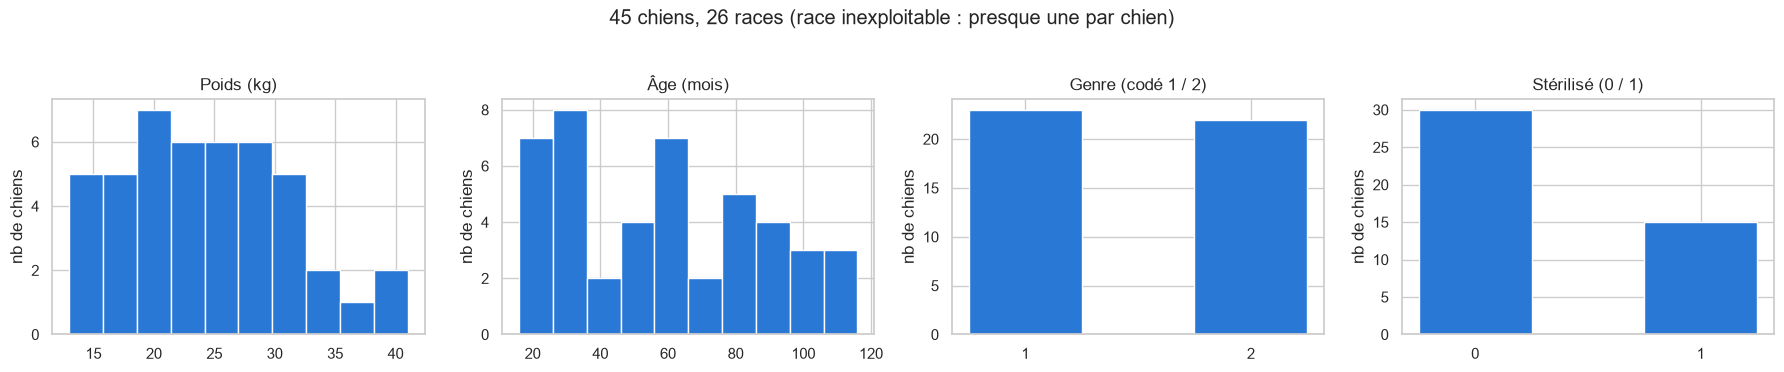

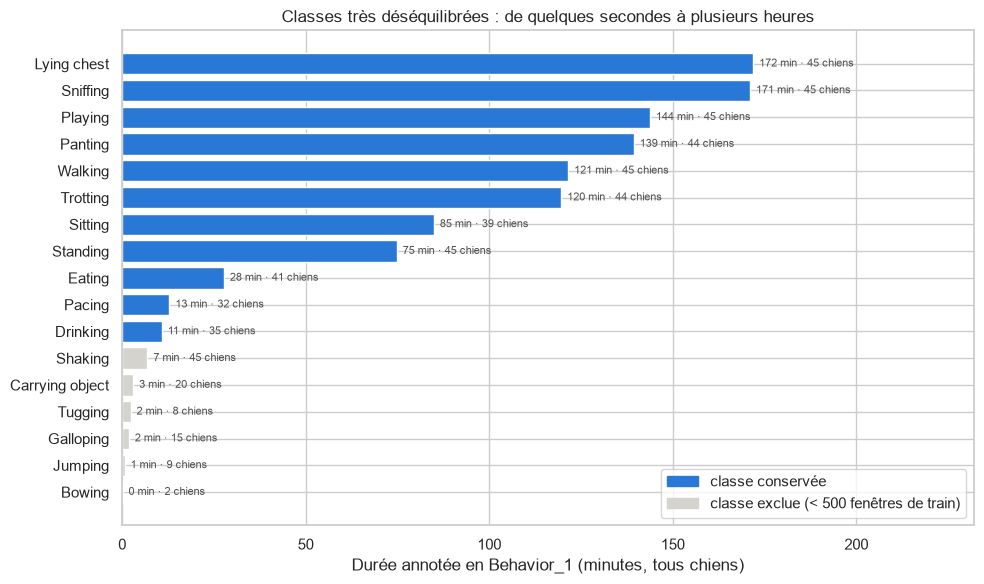

In [3]:
P.plot_profils(dogs); plt.show()
P.plot_frequences(moves, P.table("04_classes_general").set_index("target")); plt.show()

- **Profils** : une seule valeur par chien. Attention, avec 36 chiens d'apprentissage (cf 2.), un modèle peut s'en servir pour
  « reconnaître le chien » plutôt que pour généraliser : testé en expérience séparée (E4).
- **Déséquilibre fort** → métrique principale **F1 macro** (chaque classe compte autant).
- **Classes rares** : moins de 500 fenêtres dans le train → exclues du train **et** du test (seuil décidé
  sur le train). 11 classes conservées sur 17 ; elles ne représentent que **0,7 %** des fenêtres de test.
  Les scores ne portent que sur ces 11 classes.

### Visualisation interactive des signaux

In [4]:
from ipywidgets import interact, Dropdown
seances = moves[cfg.SESSION_KEYS].drop_duplicates().sort_values(cfg.SESSION_KEYS)
interact(lambda seance, capteur, label: (viz.plot_session_signals(moves, dogs, *seance, sensor=capteur,
                                                                   behavior_col=label), plt.show()),
         seance=Dropdown(options={f"Chien {d} - test {t}": (int(d), int(t)) for d, t in seances.itertuples(index=False)},
                         description="Séance"),
         capteur=Dropdown(options=cfg.SENSORS, description="Capteur"),
         label=Dropdown(options=cfg.BEHAVIOR_COLUMNS, description="Label"));

interactive(children=(Dropdown(description='Séance', options={'Chien 16 - test 1': (16, 1), 'Chien 16 - test 2…

---
## 2. Séparation train / test **par chien**

Toutes les données d'un chien sont soit en apprentissage, soit en test (36 / 9 chiens, `GroupShuffleSplit`).

**Pourquoi** : deux fenêtres voisines d'un même chien sont presque identiques (elles se chevauchent). Un split
aléatoire par fenêtre mettrait des quasi-doublons de part et d'autre et gonflerait le score. Le score de test
mesure ici ce qui nous intéresse : **la capacité à reconnaître le comportement d'un chien jamais vu**.
Le split est figé dans `data/processed/split.json` et partagé par tous les notebooks.

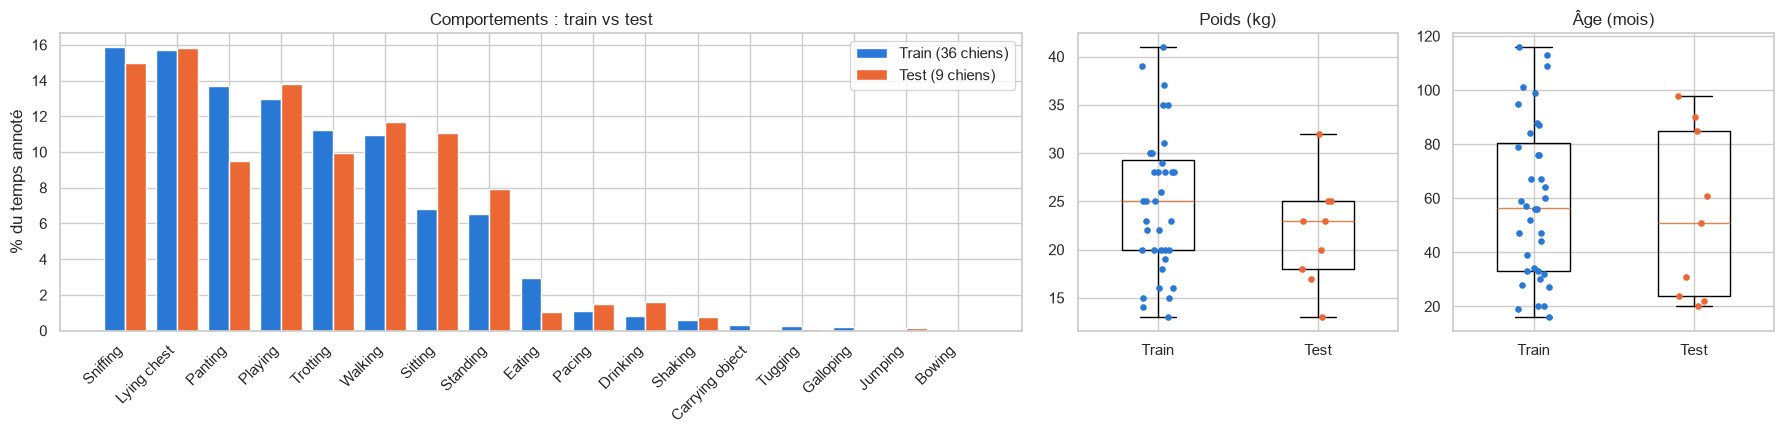

Chiens de test : [16, 30, 33, 34, 41, 55, 70, 73, 74]
Comportements absents du test : ['Galloping', 'Bowing'] (classes rares, exclues de toute façon)


In [6]:
fig, prop = P.plot_split(moves, dogs, train_ids, test_ids); plt.show()
print("Chiens de test :", list(test_ids))
print("Comportements absents du test :", prop.index[prop["Test"] == 0].tolist(), "(classes rares, exclues de toute façon)")

**Représentativité** : proportions de comportements proches entre train et test, profils comparables
(test un peu plus léger et plus jeune). Limites : avec 9 chiens, le hasard du split compte beaucoup
(Sitting 11 % du test contre 7 % du train, Eating 1 % contre 3 %) ; seul un split a été évalué.

---
## 3. Pipeline général d'entraînement et d'évaluation

```
 signaux 100 Hz ──► fenêtres (cœur 1 s, pas 0,5 s, contexte 1 / 2 / 4 s, pureté ≥ 80 %)
                     │
                     ▼
 variables par fenêtre (statistiques, fréquentiel, ratios cou/dos)      ← « feature engineering »
                     │
                     ▼
 Pipeline scikit-learn :  [standardisation] → sélection de variables (forêt rapide) → classifieur
                     │
                     ▼
 GridSearchCV  · StratifiedGroupKFold à 5 plis, groupé par chien · score = F1 macro
                     │
                     ▼
 choix du modèle sur la CV uniquement  ──►  évaluation UNE fois sur les 9 chiens de test
```

| Brique | Choix | Justification |
|---|---|---|
| Formatage | 1 fenêtre = 1 exemple, label = comportement majoritaire du cœur de 1 s | assez court pour suivre les changements de comportement |
| Variables | 20 signaux (12 axes + 4 normes + 4 dérivées de norme) × moyenne, écart-type, min, max ; fréquence dominante, énergie, entropie spectrales des normes ; ratios cou / dos | sens physique : orientation (posture), rythme (allure), mouvements de tête (activités) |
| Validation | `StratifiedGroupKFold(5)` par chien | même logique que le split : chaque pli valide sur des chiens non vus |
| Modèles | 2 `DummyClassifier` (plancher), régression logistique, forêt aléatoire, XGBoost | du linéaire interprétable au boosting ; classes pondérées (`balanced`) |
| Grilles | LR : `C` ∈ {0,1 ; 1 ; 10} · RF : 100/300 arbres × profondeur {∞, 15, 25} × feuilles {1, 5} · XGB : 200/400 arbres × profondeur {4, 6, 8} × taux {0,05 ; 0,1} | 3 à 12 combinaisons × 5 plis par modèle |
| Sélection de variables | `SelectFromModel` (forêt de 50 arbres, seuil = importance moyenne), **dans** le pipeline | ajustée sur chaque pli d'apprentissage : pas de fuite ; mise en cache, calculée une fois par pli |
| Métriques | **F1 macro** (principale), exactitude, exactitude équilibrée, F1 pondéré, scores **par chien** | classes déséquilibrées ; le chien est l'unité statistique |
| Règle d'or | aucun choix (modèle, variables, lissage, seuils) n'est fait sur le test | le score de test reste une estimation honnête |

Le pipeline du modèle retenu, tel qu'il est enregistré :

In [7]:
display(general["model"])
print("Hyperparamètres retenus :", general["best_params"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('selecteur', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](11,)","[ 0, 1, 2,..., 8, 9,10]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](282,)","['ABack_x_mean_w1s','ABack_y_mean_w1s','ABack_z_mean_w1s',..., 'GNeck_norm_entropie_w4s','ratio_A_cou_dos_w4s','ratio_G_cou_dos_w4s']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,282
,"estimator estimator: objectThe base estimator from which the transformer is built.This can be both a fitted (if ``prefit`` is set to True)or a non-fitted estimator. The estimator should have a``feature_importances_`` or ``coef_`` attribute after fitting.Otherwise, the ``importance_getter`` parameter should be used.",RandomForestC...ndom_state=42)
,"threshold threshold: str or float, default=NoneThe threshold value to use for feature selection. Features whoseabsolute importance value is greater or equal are kept while the othersare discarded. If ""median"" (resp. ""mean""), then the ``threshold`` valueis the median (resp. the mean) of the feature importances. A scalingfactor (e.g., ""1.25*mean"") may also be used. If None and if theestimator has a parameter penalty set to l1, either explicitlyor implicitly (e.g, Lasso), the threshold used is 1e-5.Otherwise, ""mean"" is used by default.",'mean'
,"prefit prefit: bool, default=FalseWhether a prefit model is expected to be passed into the constructordirectly or not.If `True`, `estimator` must be a fitted estimator.If `False`, `estimator` is fitted and updated by calling`fit` and `partial_fit`, respectively.",False


Hyperparamètres retenus : {'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 400}


---
## 4. Approche par fenêtres : modèle général (11 classes)

### Les variables séparent-elles les comportements ? (chiens d'apprentissage uniquement)

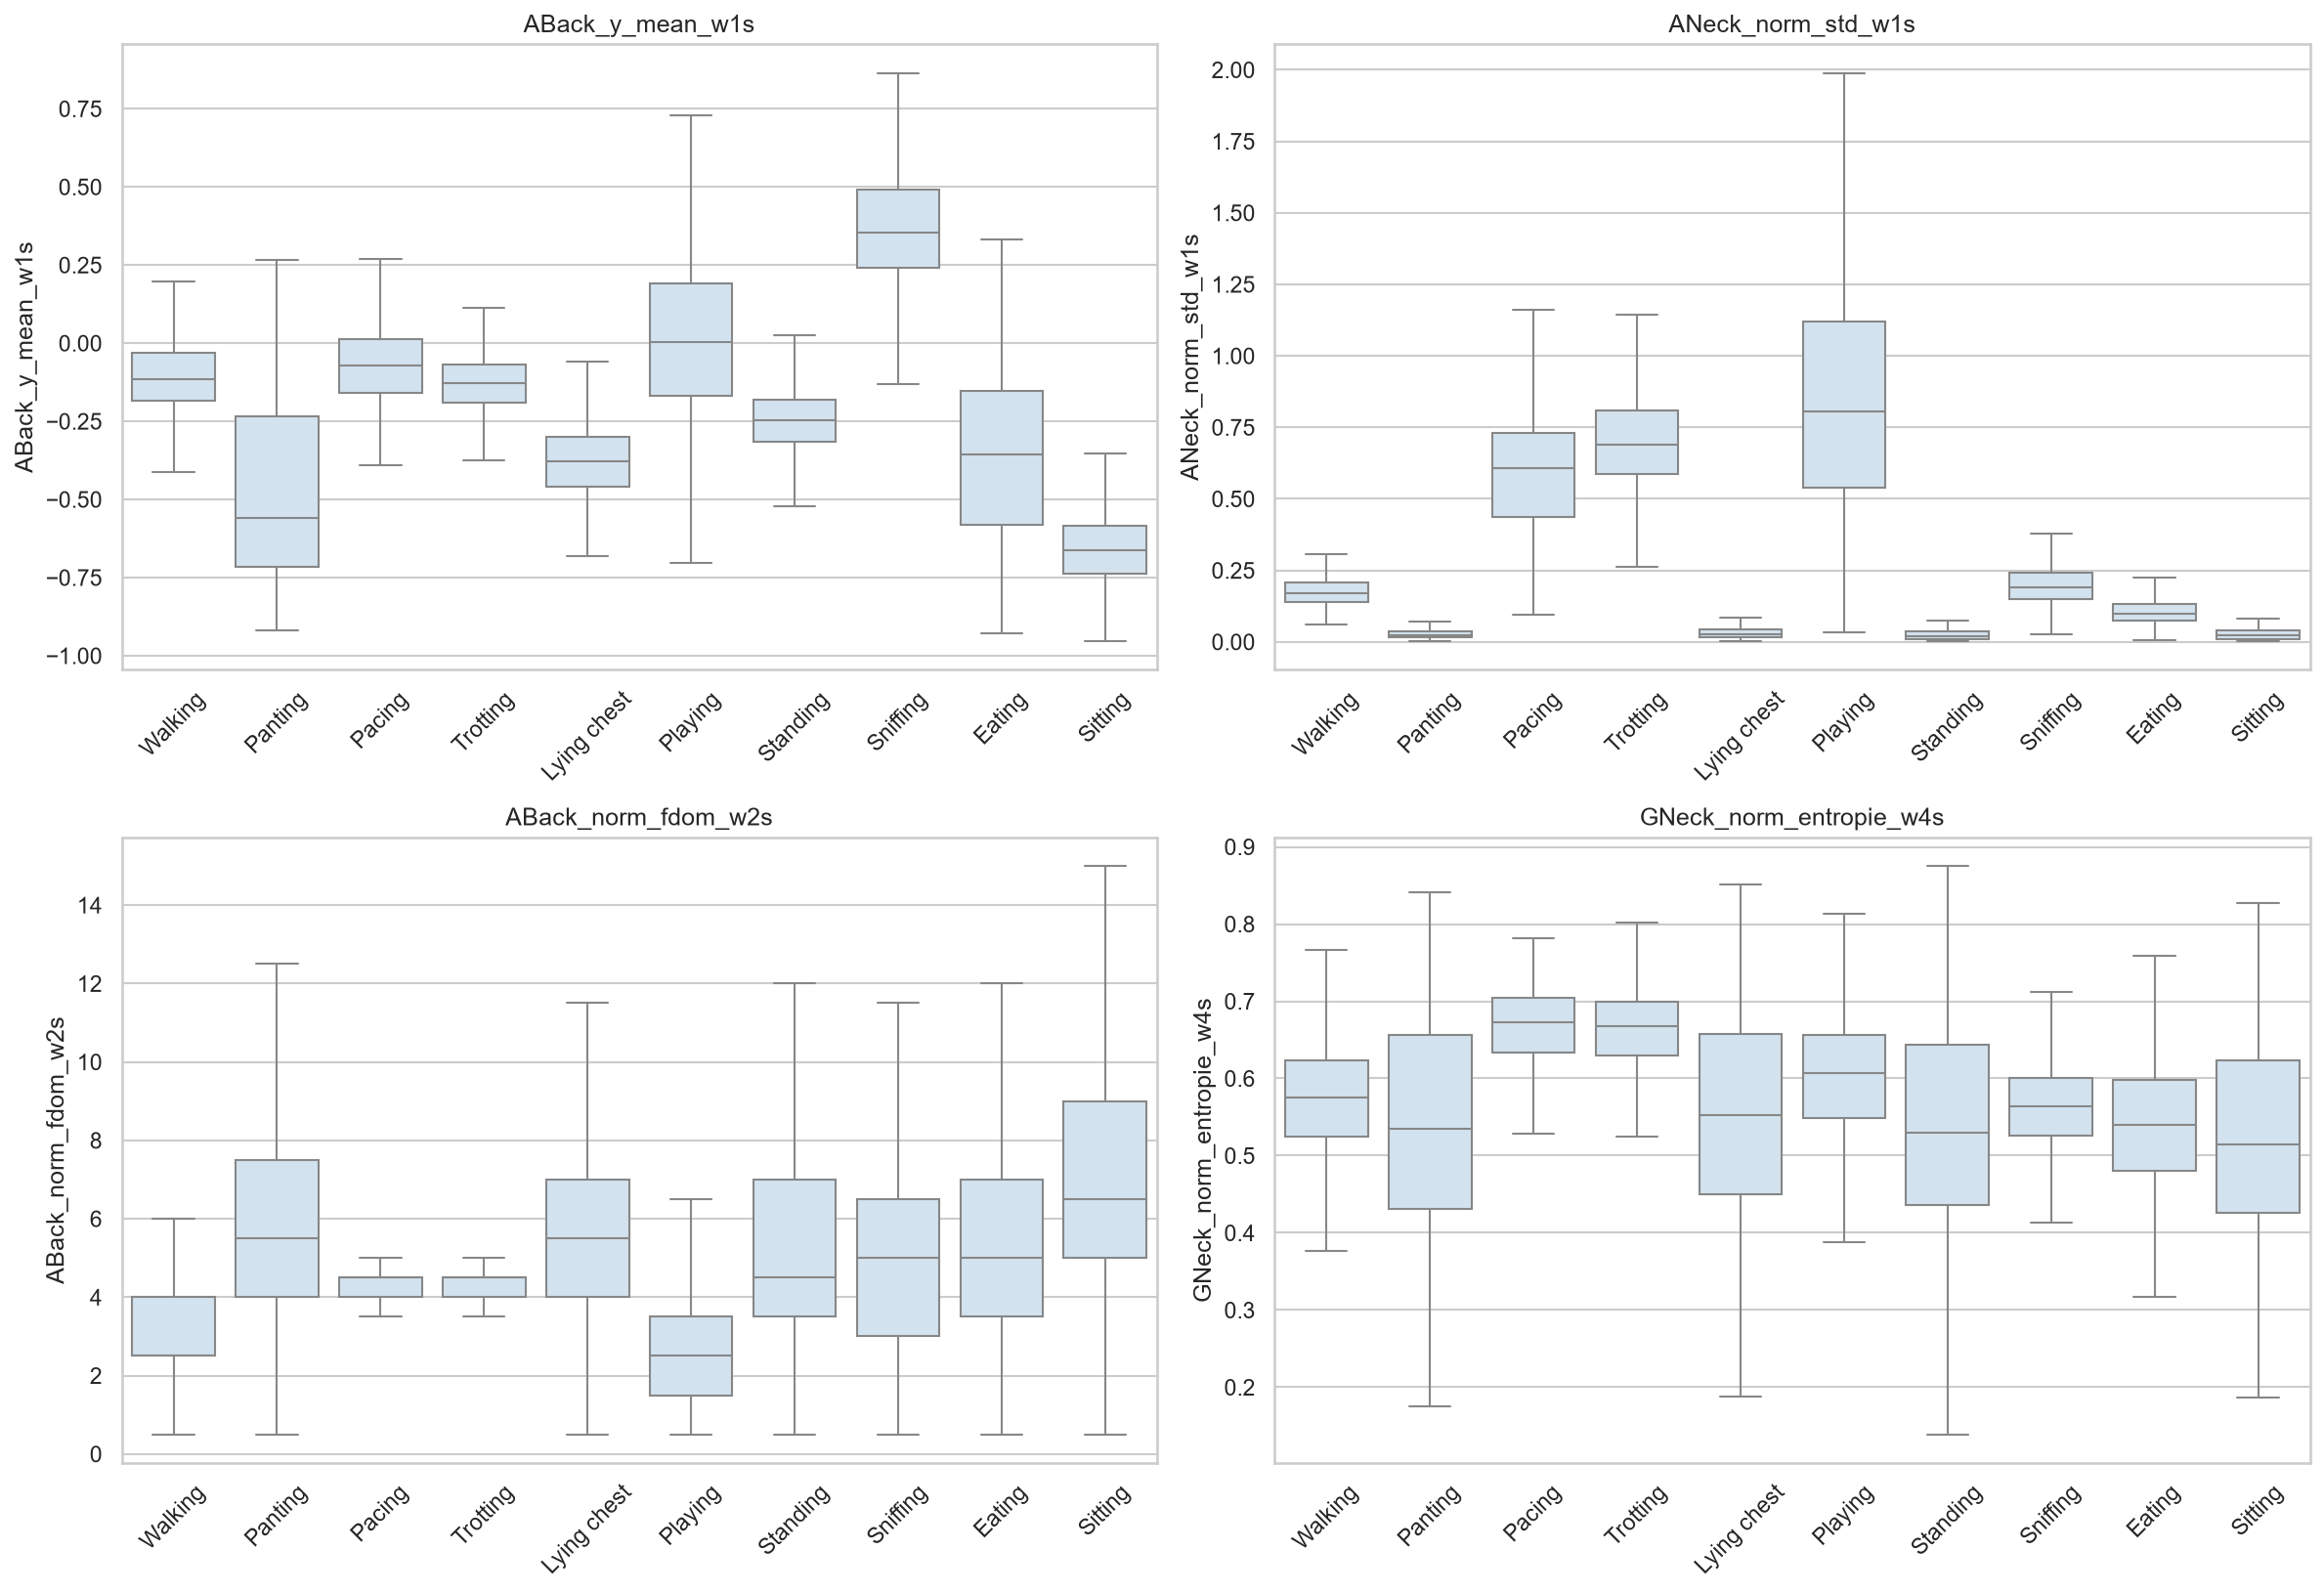

In [8]:
P.figure("03_variables_par_comportement", width=950)

La moyenne de l'axe y du dos sépare les postures (gravité) ; l'écart-type de la norme du cou capte les
mouvements de tête (flairer, manger) ; la fréquence dominante sépare les allures.

### Quatre expériences, du plus simple au plus riche

| Expérience | Variables | Nb | Question posée |
|---|---|:---:|---|
| **E1** · moy. + écart-type, 1 s | moyenne et écart-type des 20 signaux sur 1 s + 2 ratios | 42 | point de départ minimal |
| **E2** · variables complètes, 1 s | + min, max et variables fréquentielles | 94 | les variables supplémentaires aident-elles ? |
| **E3** · multi-échelle 1-2-4 s | les 94 variables sur 1 s, 2 s et 4 s autour du même cœur | 282 | le **contexte temporel** aide-t-il ? |
| **E4** · multi-échelle + profil | E3 + poids, âge, genre, stérilisation | 286 | le **profil du chien** aide-t-il ? |

Les quatre expériences utilisent **exactement les mêmes fenêtres** : seules les variables changent.

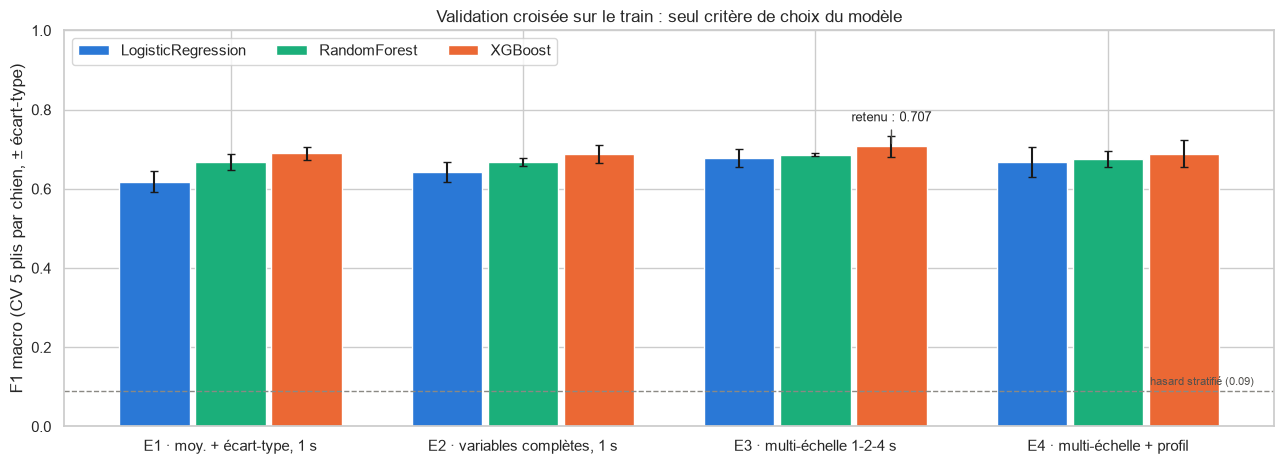

Durée totale des recherches d'hyperparamètres (notebook 04) : 1 h 39 min | construction des 211 761 fenêtres multi-échelles : 36 s (notebook 03)


experience,"E1 · moy. + écart-type, 1 s","E2 · variables complètes, 1 s",E3 · multi-échelle 1-2-4 s,E4 · multi-échelle + profil
modele,,,,
LogisticRegression,1.3 min,1.9 min,3.9 min,6.2 min
RandomForest,6.8 min,8.4 min,14.2 min,13.9 min
XGBoost,5.0 min,6.2 min,16.3 min,15.0 min


In [9]:
cv04 = P.table("04_resultats_cv_general")
P.plot_cv_experiences(cv04); plt.show()
print(f"Durée totale des recherches d'hyperparamètres (notebook 04) : {P.durees(cv04)} "
      f"| construction des 211 761 fenêtres multi-échelles : 36 s (notebook 03)")
duree = cv04.pivot(index="modele", columns="experience", values="duree_s").drop(index=list(modeling.DUMMY_MODELS))
display((duree.rename(columns=P.NOMS_EXPERIENCES) / 60).round(1).style.format("{:.1f} min")
        .set_caption("Durée de chaque GridSearchCV (5 plis × grille)"))

**Lecture** :
- **E1 → E2** : pas de gain net, sauf pour la régression logistique ; **E2 → E3** : le **contexte multi-échelle** apporte le gain le plus
  régulier, pour les trois modèles ;
- **E4** : ajouter le profil du chien **dégrade** la CV (0,707 → 0,688) : les variables de profil servent à
  reconnaître les chiens d'apprentissage, pas à généraliser (voir discussion) ;
- les écarts-types (± 0,02 à 0,03) rappellent que des écarts de 0,01 ne départagent pas deux modèles.

**Modèle retenu, sur la CV uniquement** : XGBoost / E3, F1 macro CV = 0,707 ± 0,026.

### Résultats sur les 9 chiens de test

In [10]:
t04 = P.table("04_resultats_test_general")
t04["experience"] = t04["experience"].map(P.NOMS_EXPERIENCES).fillna("plancher")
colonnes = ["experience", "modele", "f1_macro_cv", "f1_macro", "exactitude", "exactitude_equilibree", "f1_ponderee"]
display(t04[colonnes].round(3).style.hide(axis="index")
        .apply(lambda r: ["font-weight: bold" if "E3" in str(r["experience"]) else "" for _ in r], axis=1))

experience,modele,f1_macro_cv,f1_macro,exactitude,exactitude_equilibree,f1_ponderee
"E1 · moy. + écart-type, 1 s",XGBoost,0.690000,0.690000,0.765000,0.715000,0.772000
"E2 · variables complètes, 1 s",XGBoost,0.688000,0.701000,0.773000,0.721000,0.779000
E3 · multi-échelle 1-2-4 s,XGBoost,0.707000,0.720000,0.792000,0.723000,0.795000
E4 · multi-échelle + profil,XGBoost,0.688000,0.721000,0.791000,0.734000,0.795000
plancher,Dummy_majoritaire,0.025000,0.026000,0.167000,0.091000,0.048000
plancher,Dummy_stratifie,0.090000,0.088000,0.121000,0.089000,0.120000


Le **F1 de test (0,720) est cohérent avec la CV (0,707)** : la sélection par CV n'a pas produit d'estimation
optimiste. Sur le test, E4 égale E3 (0,721 contre 0,720) : le profil n'apporte rien non plus, et de toute
façon on ne départage jamais sur le test.

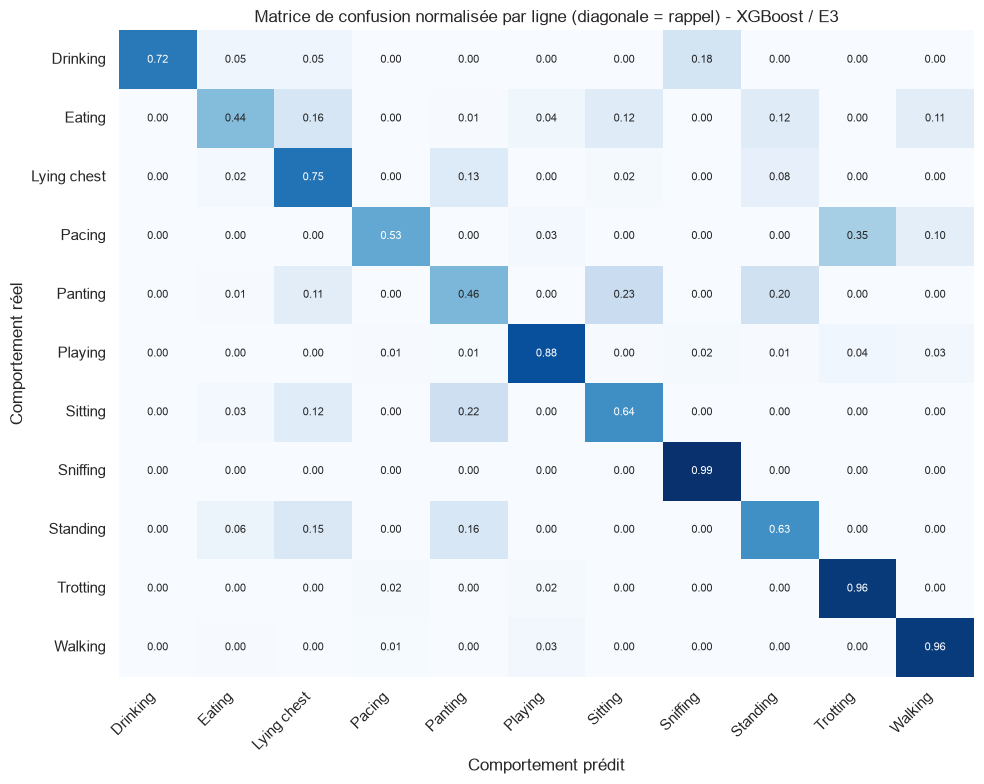

In [11]:
evaluation.plot_confusion(preds["target"], preds["pred"], classes,
                          ax=plt.subplots(figsize=(10, 8))[1],
                          title="Matrice de confusion normalisée par ligne (diagonale = rappel) - XGBoost / E3")
plt.tight_layout(); plt.show()

Deux types d'erreurs :
- **la locomotion et le flairage sont très bien reconnus** (rappel 0,96 à 0,99). Pacing est confondu
  avec le trot (35 %) : deux allures proches ;
- **les comportements statiques se mélangent** : Panting (halètement) est prédit Sitting (23 %) ou Standing
  (20 %), et réciproquement. Ce n'est pas seulement un défaut du modèle : on halète en étant assis ou
  debout, les labels ne sont pas exclusifs.

### Évaluation stricte et évaluation flexible (Behavior_2 et Behavior_3)

- **Stricte** (score officiel) : la prédiction doit être égale à `Behavior_1`.
- **Flexible** (lecture complémentaire) : la prédiction est acceptée si elle figure dans `Behavior_1`, `2`
  **ou** `3`, c'est-à-dire si le chien est réellement en train de faire ce qui est prédit.

In [12]:
preds["ok_strict"] = preds["pred"] == preds["target"]
preds["ok_flexible"] = evaluation.flexible_correct(preds, "pred")
print(f"Exactitude stricte : {preds['ok_strict'].mean():.3f} | flexible : {preds['ok_flexible'].mean():.3f} "
      f"→ {(preds['ok_flexible'] & ~preds['ok_strict']).sum() / (~preds['ok_strict']).sum():.0%} des erreurs strictes "
      "désignent un comportement réellement en cours")
g = preds.groupby("target")[["ok_strict", "ok_flexible"]].mean()
g["gain"] = g["ok_flexible"] - g["ok_strict"]
display(g.sort_values("gain", ascending=False).round(3).rename(
    columns={"ok_strict": "exactitude stricte", "ok_flexible": "exactitude flexible"}).T)

Exactitude stricte : 0.792 | flexible : 0.903 → 53% des erreurs strictes désignent un comportement réellement en cours


target,Panting,Eating,Sitting,Standing,Lying chest,Playing,Drinking,Pacing,Sniffing,Trotting,Walking
exactitude stricte,0.459,0.441,0.635,0.632,0.746,0.878,0.722,0.526,0.995,0.962,0.956
exactitude flexible,0.897,0.877,0.849,0.805,0.883,0.906,0.722,0.526,0.995,0.962,0.956
gain,0.438,0.436,0.213,0.173,0.138,0.028,0.000,0.000,0.000,0.000,0.000


Les gains se concentrent exactement sur les classes confondues dans la matrice : Panting (+0,44),
Eating (+0,44), Sitting, Standing, Lying chest. Locomotion et flairage ne gagnent rien : leurs erreurs sont de
vraies erreurs. Une grande part de l'erreur mesurée vient donc de la **formulation mono-label d'un problème
multi-label**.

### Le score par chien : la vraie mesure de fiabilité

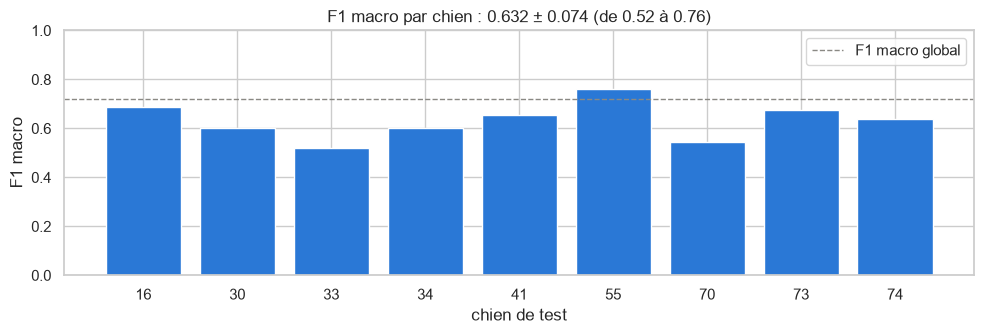

In [13]:
par_chien = evaluation.per_dog_scores(preds)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(par_chien["DogID"].astype(str), par_chien["f1_macro"], color=P.BLEU)
ax.axhline(evaluation.compute_metrics(preds["target"], preds["pred"], classes)["f1_macro"], color=P.GRIS, ls="--",
           lw=1, label="F1 macro global")
ax.set_ylim(0, 1); ax.set_xlabel("chien de test"); ax.set_ylabel("F1 macro"); ax.legend()
ax.set_title(f"F1 macro par chien : {par_chien['f1_macro'].mean():.3f} ± {par_chien['f1_macro'].std():.3f} "
             f"(de {par_chien['f1_macro'].min():.2f} à {par_chien['f1_macro'].max():.2f})")
plt.tight_layout(); plt.show()

L'écart entre chiens (0,52 à 0,76) est **bien plus grand** que les écarts entre expériences (0,01 à 0,03) :
la variabilité individuelle est la principale limite.

### Frise interactive des prédictions
Axe horizontal = vrai temps de la séance (les trous sont les fenêtres exclues). Point vert : prédiction
présente dans `Behavior_1/2/3` ; croix rouge : prédiction hors annotations. Les tableaux, eux, restent stricts.

In [14]:
seances_test = preds[["DogID", "TestNum"]].drop_duplicates().sort_values(["DogID", "TestNum"])
def frise(seance, prediction):
    d, t = seance
    col = {"brute": "pred", f"lissée (k = {K_LISSAGE}, partie 7)": "pred_lisse"}[prediction]
    viz.plot_timeline(preds[(preds["DogID"] == d) & (preds["TestNum"] == t)], pred_col=col,
                      title=f"Chien {d} - test {t} - prédiction {prediction}").show()
interact(frise, seance=Dropdown(options={f"Chien {d} - test {t}": (d, t) for d, t in seances_test.itertuples(index=False)},
                                description="Séance"),
         prediction=Dropdown(options=["brute", f"lissée (k = {K_LISSAGE}, partie 7)"], description="Prédiction"));

interactive(children=(Dropdown(description='Séance', options={'Chien 16 - test 1': (16, 1), 'Chien 16 - test 2…

---
## 5. Modèles spécifiques : posture, locomotion, activité

**Motivation** : puisque les labels ne sont pas exclusifs, on entraîne un modèle par famille dont les
classes, elles, s'excluent : posture (couché, assis, debout), locomotion (marche, trot, amble, galop),
activité (flairer, manger, boire, jouer, haleter). Le label de la famille est cherché dans `Behavior_1`, `2`
ou `3` : un chien qui halète en étant debout fournit aussi un exemple de posture « debout ».
Même protocole et mêmes 282 variables (E3) que le modèle général.

In [15]:
cv05 = P.table("05_resultats_cv_specifiques")
meilleurs05 = (cv05[~cv05["modele"].str.startswith("Dummy")].sort_values("f1_macro_cv_moy", ascending=False)
               .groupby("tache", sort=False).head(1).set_index("tache").loc[list(cfg.FAMILIES)])
display(meilleurs05[["modele", "f1_macro_cv_moy", "f1_macro_cv_std", "f1_macro_train_moy", "n_variables_retenues"]]
        .round(3))
print(f"Durée totale des recherches d'hyperparamètres (notebook 05) : {P.durees(cv05)}")

,modele,f1_macro_cv_moy,f1_macro_cv_std,f1_macro_train_moy,n_variables_retenues
tache,,,,,
posture,LogisticRegression,0.783,0.032,0.837,55
locomotion,XGBoost,0.827,0.032,1.000,64
activite,XGBoost,0.937,0.024,1.000,78


Durée totale des recherches d'hyperparamètres (notebook 05) : 20 min 53 s


**Comparaison équitable avec le modèle général** : sur les fenêtres de test **communes** (le comportement de la
famille est aussi le `Behavior_1`), F1 macro calculé sur les classes de la famille ; une prédiction du modèle
général hors de la famille (ex. « Panting » pour un chien debout) compte comme une erreur.

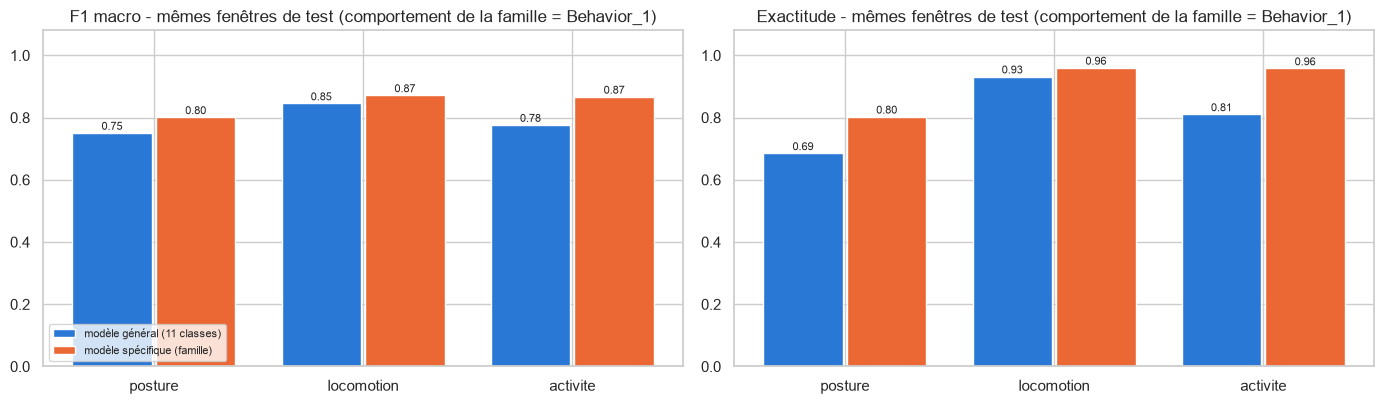

,famille,modele_specifique,classes_evaluees,n_fenetres_communes,f1_macro_general,f1_macro_specifique,n_fenetres_specifique_total,part_couverte_seulement_par_specifique
0,posture,LogisticRegression,"Lying chest, Sitting, Standing",10051,0.751,0.801,14316,0.298
1,locomotion,XGBoost,"Pacing, Trotting, Walking",6235,0.845,0.872,6984,0.107
2,activite,XGBoost,"Drinking, Eating, Panting, Playing, Sniffing",11367,0.776,0.867,15679,0.275


In [16]:
fen_test = P.load_windows_for_dogs(test_ids).merge(dogs[["DogID"] + cfg.STATIC_FEATURES], on="DogID", how="left")
comparaisons = []
for fam, r in meilleurs05.iterrows():
    b = modeling.load_bundle(fam, general["experiment"], r["modele"])
    te = labels.select_task_windows(fen_test, fam, min_purity=cfg.MIN_PURITY)
    te = te[te["target"].isin(b["label_encoder"].classes_)]
    res = te[["window_id", "DogID", "target", "behavior_1"]].assign(pred=modeling.predict(b, te)[0])
    comparaisons.append({"famille": fam, "modele_specifique": r["modele"],
                         **evaluation.compare_general_specific(preds, res, list(b["label_encoder"].classes_))})
comp05 = pd.DataFrame(comparaisons)
P.plot_general_vs_specifique(comp05); plt.show()
display(comp05[["famille", "modele_specifique", "classes_evaluees", "n_fenetres_communes", "f1_macro_general",
                "f1_macro_specifique", "n_fenetres_specifique_total", "part_couverte_seulement_par_specifique"]].round(3))

**Métriques retenues pour comparer** : le **F1 macro** (métrique du projet, sensible aux classes rares de
chaque famille) et l'**exactitude** (lecture intuitive), toutes deux sur les mêmes fenêtres, plus la
**couverture** : part des fenêtres de test que seul le modèle spécifique sait traiter (comportement de la
famille présent en `Behavior_2/3` uniquement).

**Lecture** :
- les modèles spécifiques font mieux sur la posture, l'activité et le comportement : séparer les familles retire une partie
  des confusions structurelles (halètement contre posture) ;
- ils apportent surtout un **gain de couverture** : environ 30 % des fenêtres de posture et d'activité
  n'existent pas pour le modèle général (le comportement n'y est pas `Behavior_1`) ;
- limite : trois modèles à combiner pour décrire une fenêtre, et chacun suppose qu'un comportement de sa
  famille est en cours. C'est une première approximation d'une approche **multi-label**.

---
## 6. Une approche différente : extraction automatique avec tsfresh

**Principe** : tsfresh reçoit des séries temporelles « brutes » (format long : identifiant de fenêtre, temps,
valeur) et calcule pour chaque série des centaines de descripteurs génériques (statistiques, quantiles,
autocorrélations, coefficients de Fourier, entropies, comptages de pics...) : 2 128 variables ici pour les 4
signaux, après retrait des constantes (réglage `efficient`). Il ne décide pas des fenêtres : on lui donne **les mêmes cœurs de 1 s** que l'approche 1.

**Protocole équitable** : mêmes fenêtres, même tâche, mêmes chiens, même CV, test à la fin. Pour tenir le
temps de calcul, tsfresh ne reçoit que les **4 normes** et un **sous-échantillon du train** (au plus 1 500
fenêtres par classe, 15 095 fenêtres) ; le test est complet. L'approche 1 est **réentraînée sur le même
sous-échantillon**. La sélection de variables propre à tsfresh (`select_features`) n'est pas utilisée : elle
s'ajusterait sur les labels hors de la CV (fuite) ; c'est la même sélection dans le pipeline qui s'applique.

In [17]:
cv06, t06 = P.table("06_resultats_cv_tsfresh"), P.table("06_resultats_test_tsfresh")
t06["experience"] = t06["experience"].map(P.NOMS_TSFRESH)
cv06["experience"] = cv06["experience"].map(P.NOMS_TSFRESH)
display(cv06[["experience", "modele", "f1_macro_cv_moy", "f1_macro_cv_std", "n_variables", "n_variables_retenues"]]
        .round(3).style.hide(axis="index").set_caption("Validation croisée (sous-échantillon du train)"))
display(t06[["experience", "modele", "f1_macro", "exactitude", "exactitude_equilibree"]].round(3)
        .style.hide(axis="index").set_caption("Test (27 654 fenêtres, 9 chiens)"))

couts = pd.DataFrame({
    "étape": ["fenêtres + 282 variables (approche 1)", "tsfresh : train (sous-échantillon)", "tsfresh : test"],
    "fenêtres": [211_761, 15_095, 27_654],
    "durée": ["36 s", "22 min 43 s", "42 min 52 s"],
    "durée (s)": [36, 22 * 60 + 43, 42 * 60 + 52]})
couts["ms par fenêtre"] = (1000 * couts["durée (s)"] / couts["fenêtres"]).round(2)
display(couts.drop(columns="durée (s)").style.hide(axis="index").set_caption("Coût d'extraction des variables"))

experience,modele,f1_macro_cv_moy,f1_macro_cv_std,n_variables,n_variables_retenues
Fenêtres E3 (sous-échantillon),XGBoost,0.717000,0.051000,282,86
Fenêtres E3 (sous-échantillon),RandomForest,0.704000,0.049000,282,86
Fenêtres E3 (sous-échantillon),Dummy_majoritaire,0.012000,0.002000,282,282
"tsfresh seul (4 normes, 1 s)",XGBoost,0.671000,0.018000,2128,423
"tsfresh seul (4 normes, 1 s)",RandomForest,0.644000,0.025000,2128,423
"tsfresh seul (4 normes, 1 s)",Dummy_majoritaire,0.012000,0.002000,2128,2128
Fenêtres E3 + tsfresh,XGBoost,0.729000,0.040000,2410,456
Fenêtres E3 + tsfresh,RandomForest,0.705000,0.040000,2410,456
Fenêtres E3 + tsfresh,Dummy_majoritaire,0.012000,0.002000,2410,2410


experience,modele,f1_macro,exactitude,exactitude_equilibree
Fenêtres E3 (sous-échantillon),XGBoost,0.719000,0.786000,0.760000
"tsfresh seul (4 normes, 1 s)",XGBoost,0.638000,0.702000,0.680000
Fenêtres E3 + tsfresh,XGBoost,0.743000,0.796000,0.787000


étape,fenêtres,durée,ms par fenêtre
fenêtres + 282 variables (approche 1),211761,36 s,0.170000
tsfresh : train (sous-échantillon),15095,22 min 43 s,90.290000
tsfresh : test,27654,42 min 52 s,93.010000


**Coût** : environ **550 fois plus de temps par fenêtre** pour tsfresh (93 ms contre 0,17 ms, avec 4 processus
en parallèle), alors qu'il ne traite que 4 signaux sur 1 s, contre 20 signaux sur trois échelles pour l'approche 1.

### Comparaison appariée par chien (sortie du notebook 06)

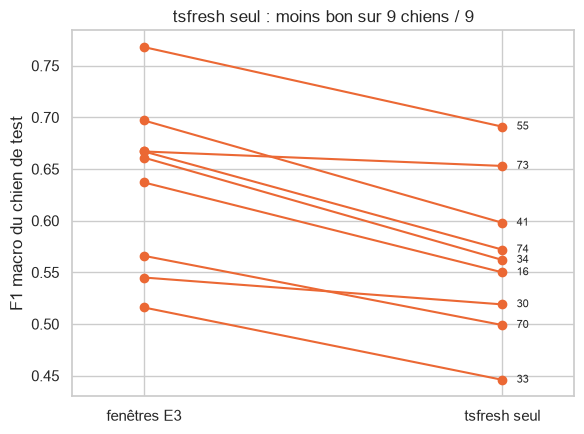

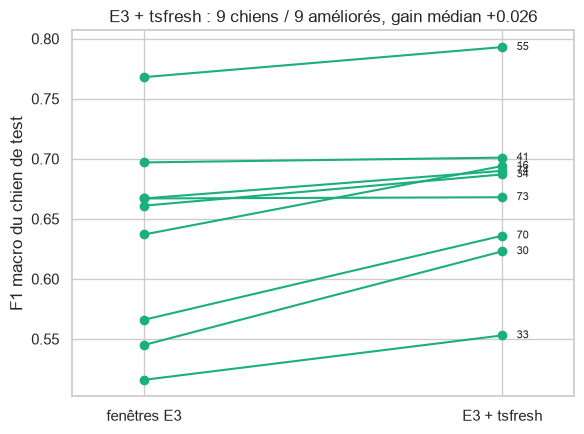

Test de Wilcoxon apparié (9 chiens) : p = 0.004 (plus petite valeur possible avec 9 chiens : 0.004)


In [18]:
# Scores par chien relevés dans la sortie du notebook 06 (prédictions non réenregistrées)
t06_chiens = pd.DataFrame({
    "DogID": [16, 30, 33, 34, 41, 55, 70, 73, 74],
    "fenetres_E3": [0.637, 0.545, 0.516, 0.661, 0.697, 0.768, 0.566, 0.667, 0.667],
    "tsfresh_seul": [0.550, 0.519, 0.446, 0.562, 0.598, 0.691, 0.499, 0.653, 0.572],
    "E3_plus_tsfresh": [0.694, 0.623, 0.553, 0.687, 0.701, 0.793, 0.636, 0.668, 0.690]}).set_index("DogID")
from scipy.stats import wilcoxon
P.plot_par_chien_apparie(t06_chiens, "fenetres_E3", "tsfresh_seul", "tsfresh seul : moins bon sur 9 chiens / 9",
                         "fenêtres E3", "tsfresh seul"); plt.show()
gain = t06_chiens["E3_plus_tsfresh"] - t06_chiens["fenetres_E3"]
P.plot_par_chien_apparie(t06_chiens, "fenetres_E3", "E3_plus_tsfresh",
                         f"E3 + tsfresh : {(gain > 0).sum()} chiens / 9 améliorés, gain médian {gain.median():+.3f}",
                         "fenêtres E3", "E3 + tsfresh"); plt.show()
print(f"Test de Wilcoxon apparié (9 chiens) : p = {wilcoxon(gain).pvalue:.3f} "
      f"(plus petite valeur possible avec 9 chiens : {2 / 2**9:.3f})")

**Conclusion tsfresh** : seul, il fait moins bien que nos variables sur chacun des 9 chiens. Combiné à
elles, il apporte un gain **faible mais systématique** (+0,026 en médiane, 9 chiens sur 9). Ce gain est petit
devant l'écart entre chiens (environ 25 points) et se paie en temps de calcul et en interprétabilité
(`GNeck_norm__c3__lag_2` est moins parlant que « orientation moyenne du dos »).

**Limite** : l'équité porte sur les fenêtres et le protocole, **pas sur l'information disponible**.
tsfresh ne reçoit que les 4 normes (ni les axes bruts ni l'orientation de la gravité, déterminants pour les
postures) et le cœur de 1 s (sans le contexte de 2 s et 4 s). Une partie de son retard vient de ces entrées
réduites. C'est pourquoi l'expérience « E3 + tsfresh » est la plus informative : elle montre que ses
descripteurs apportent une information **complémentaire**.


In [32]:
b = modeling.load_bundle("general", "approche1+tsfresh", "XGBoost")
ret = modeling.selected_features(b["model"], b["features"])
imp = pd.Series(b["model"].named_steps["clf"].feature_importances_, index=ret)
est_tsf = imp.index.str.startswith("tsf_")

print(f"Variables retenues : {len(ret)} sur {len(b['features'])}")
print(f"  dont tsfresh : {est_tsf.sum()} | dont E3 : {(~est_tsf).sum()} (contre 86 pour E3 seul)")
print(f"Part de l'importance totale portée par tsfresh : {imp[est_tsf].sum() / imp.sum():.0%}")
print("\n15 variables les plus importantes :")
print(imp.sort_values(ascending=False).head(15).round(4).to_string())

Variables retenues : 456 sur 2410
  dont tsfresh : 252 | dont E3 : 204 (contre 86 pour E3 seul)
Part de l'importance totale portée par tsfresh : 62%

15 variables les plus importantes :
tsf_ANeck_norm__change_quantiles__f_agg_"var"__isabs_False__qh_1.0__ql_0.0    0.1263
GNeck_norm_mean_w4s                                                           0.0529
tsf_ANeck_norm__change_quantiles__f_agg_"var"__isabs_True__qh_1.0__ql_0.0     0.0351
tsf_ABack_norm__quantile__q_0.2                                               0.0311
tsf_ANeck_norm__quantile__q_0.2                                               0.0291
tsf_ABack_norm__quantile__q_0.1                                               0.0286
tsf_GBack_norm__quantile__q_0.2                                               0.0242
ANeck_y_mean_w2s                                                              0.0207
tsf_ANeck_norm__ar_coefficient__coeff_0__k_10                                 0.0206
GBack_norm_std_w4s                               

**Attention** : lors de la sélection de variables de l'expérience E3 + tsfresh, un plus grand nombre de variables d'E3 a aussi été sélectionné. Le gain en performance du modèle pourrait être lié à cela.


### Le modèle du notebook 04 et celui du notebook 06 (même expérience E3)

In [19]:
ref04 = P.table("04_resultats_test_general").query("experience == 'multi_echelle'").iloc[0]
ref06 = P.table("06_resultats_test_tsfresh").query("experience == 'approche1_sous_echantillon'").iloc[0]
display(pd.DataFrame({
    "notebook 04 : train complet": {"fenêtres d'apprentissage": "93 124", "F1 macro CV": f"{ref04['f1_macro_cv']:.3f}",
                                    "F1 macro test": f"{ref04['f1_macro']:.3f}", "exactitude test": f"{ref04['exactitude']:.3f}",
                                    "exactitude équilibrée test": f"{ref04['exactitude_equilibree']:.3f}"},
    "notebook 06 : sous-échantillon équilibré": {"fenêtres d'apprentissage": "15 095", "F1 macro CV": f"{ref06['f1_macro_cv']:.3f}",
                                    "F1 macro test": f"{ref06['f1_macro']:.3f}", "exactitude test": f"{ref06['exactitude']:.3f}",
                                    "exactitude équilibrée test": f"{ref06['exactitude_equilibree']:.3f}"}}))

,notebook 04 : train complet,notebook 06 : sous-échantillon équilibré
fenêtres d'apprentissage,93 124,15 095
F1 macro CV,0.707,0.717
F1 macro test,0.720,0.719
exactitude test,0.792,0.786
exactitude équilibrée test,0.723,0.760


Avec **6 fois moins de fenêtres** (mais équilibrées par classe), le F1 macro de test est quasi identique
(0,719 contre 0,720) et l'exactitude équilibrée progresse (0,760 contre 0,723) : le rééquilibrage profite
aux classes rares. Le modèle est donc limité **par le nombre de chiens et leur variabilité**, pas par le
nombre de fenêtres. Les F1 de CV ne sont pas comparables (calculés sur des données différentes).

Précaution : l'écart mêle deux effets, la réduction des données **et** un nouveau réglage des
hyperparamètres (nouvelle recherche sur le sous-échantillon). C'est une bonne indication du coût du
sous-échantillonnage, pas une mesure pure.

---
## 7. Analyses complémentaires sur le modèle général

### 7.1 Lissage temporel des prédictions
Un comportement dure plusieurs secondes : on remplace les probabilités de chaque fenêtre par la **moyenne
sur les k fenêtres voisines** (fenêtre centrée, sans traverser de rupture), puis on reprend la classe la plus
probable. **k est choisi sur des prédictions hors-pli du train** (5 réentraînements, notebook 07), jamais sur
le test. Aucun label n'est utilisé.

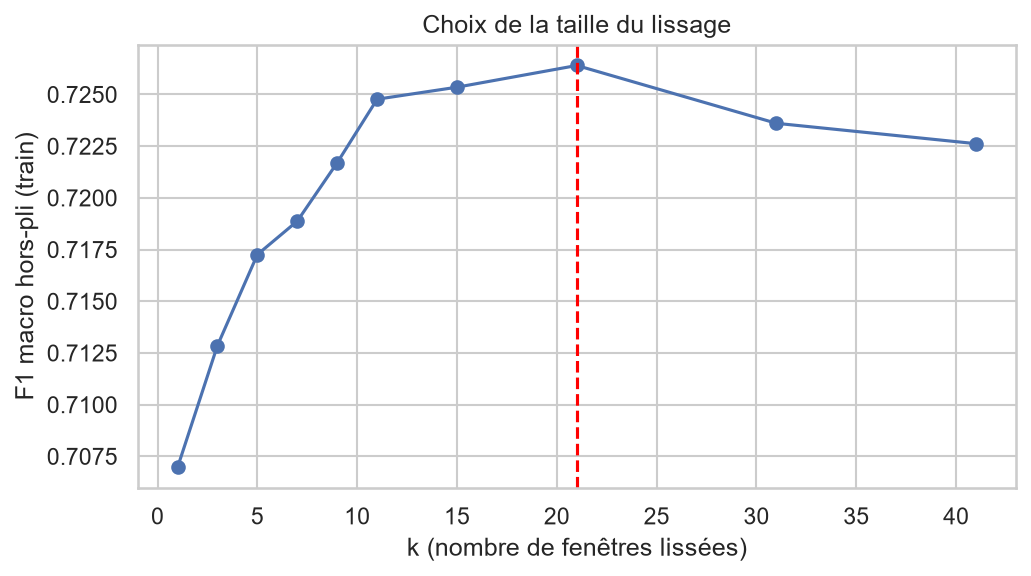

In [20]:
P.figure("07_choix_lissage", width=550)

In [21]:
avant = evaluation.compute_metrics(preds["target"], preds["pred"], classes)
apres = evaluation.compute_metrics(preds["target"], preds["pred_lisse"], classes)
flex_apres = evaluation.flexible_correct(preds, "pred_lisse").mean()
display(pd.DataFrame({"sans lissage": avant, f"lissage k = {K_LISSAGE} (≈ 11 s)": apres})
        .drop(index="n_fenetres").round(3).T)
print(f"Exactitude flexible : {preds['ok_flexible'].mean():.3f} → {flex_apres:.3f}")

pc = (evaluation.per_dog_scores(preds, "pred")[["DogID", "f1_macro"]]
      .merge(evaluation.per_dog_scores(preds, "pred_lisse")[["DogID", "f1_macro"]], on="DogID", suffixes=("_brut", "_lisse")))
print(f"Chiens améliorés : {(pc['f1_macro_lisse'] > pc['f1_macro_brut']).sum()} / {len(pc)}")
presentes = [c for c in classes if preds["target"].eq(c).any()]
par_classe = pd.DataFrame({
    "sans lissage": f1_score(preds["target"], preds["pred"], labels=presentes, average=None),
    "avec lissage": f1_score(preds["target"], preds["pred_lisse"], labels=presentes, average=None)}, index=presentes)
par_classe["écart"] = par_classe["avec lissage"] - par_classe["sans lissage"]
display(par_classe.sort_values("écart").round(3).T)

,exactitude,exactitude_equilibree,f1_macro,f1_ponderee,precision_macro,rappel_macro
sans lissage,0.792,0.723,0.720,0.795,0.734,0.723
lissage k = 21 (≈ 11 s),0.818,0.738,0.751,0.818,0.773,0.738


Exactitude flexible : 0.903 → 0.918
Chiens améliorés : 8 / 9


,Drinking,Panting,Sniffing,Walking,Sitting,Lying chest,Trotting,Standing,Playing,Pacing,Eating
sans lissage,0.826,0.438,0.978,0.947,0.683,0.756,0.931,0.614,0.912,0.584,0.255
avec lissage,0.809,0.436,0.985,0.961,0.698,0.785,0.964,0.649,0.954,0.647,0.375
écart,-0.017,-0.001,0.007,0.014,0.015,0.029,0.032,0.035,0.042,0.063,0.120


**+0,031 de F1 macro, à coût de calcul quasi nul** : plus que l'ajout de tsfresh. Le gain porte sur les
comportements longs dont chaque fenêtre est ambiguë (Eating +0,12, Pacing +0,06) ; seuls les épisodes brefs
(Drinking) perdent un peu. **Panting ne gagne rien** : ses erreurs ne sont pas ponctuelles mais structurelles
(halètement et posture simultanés). 

**Limite** : la fenêtre centrée utilise environ 5 s de « futur » ; en temps
réel, il faudrait un lissage causal.

### 7.2 Projection UMAP des erreurs
UMAP place chaque fenêtre de test (91 variables retenues) sur un plan en **préservant les voisinages** :
deux fenêtres proches dans l'espace des variables restent proches. Outil de **diagnostic** seulement :
les distances entre nuages éloignés n'ont pas de sens. Même nuage, trois colorations.

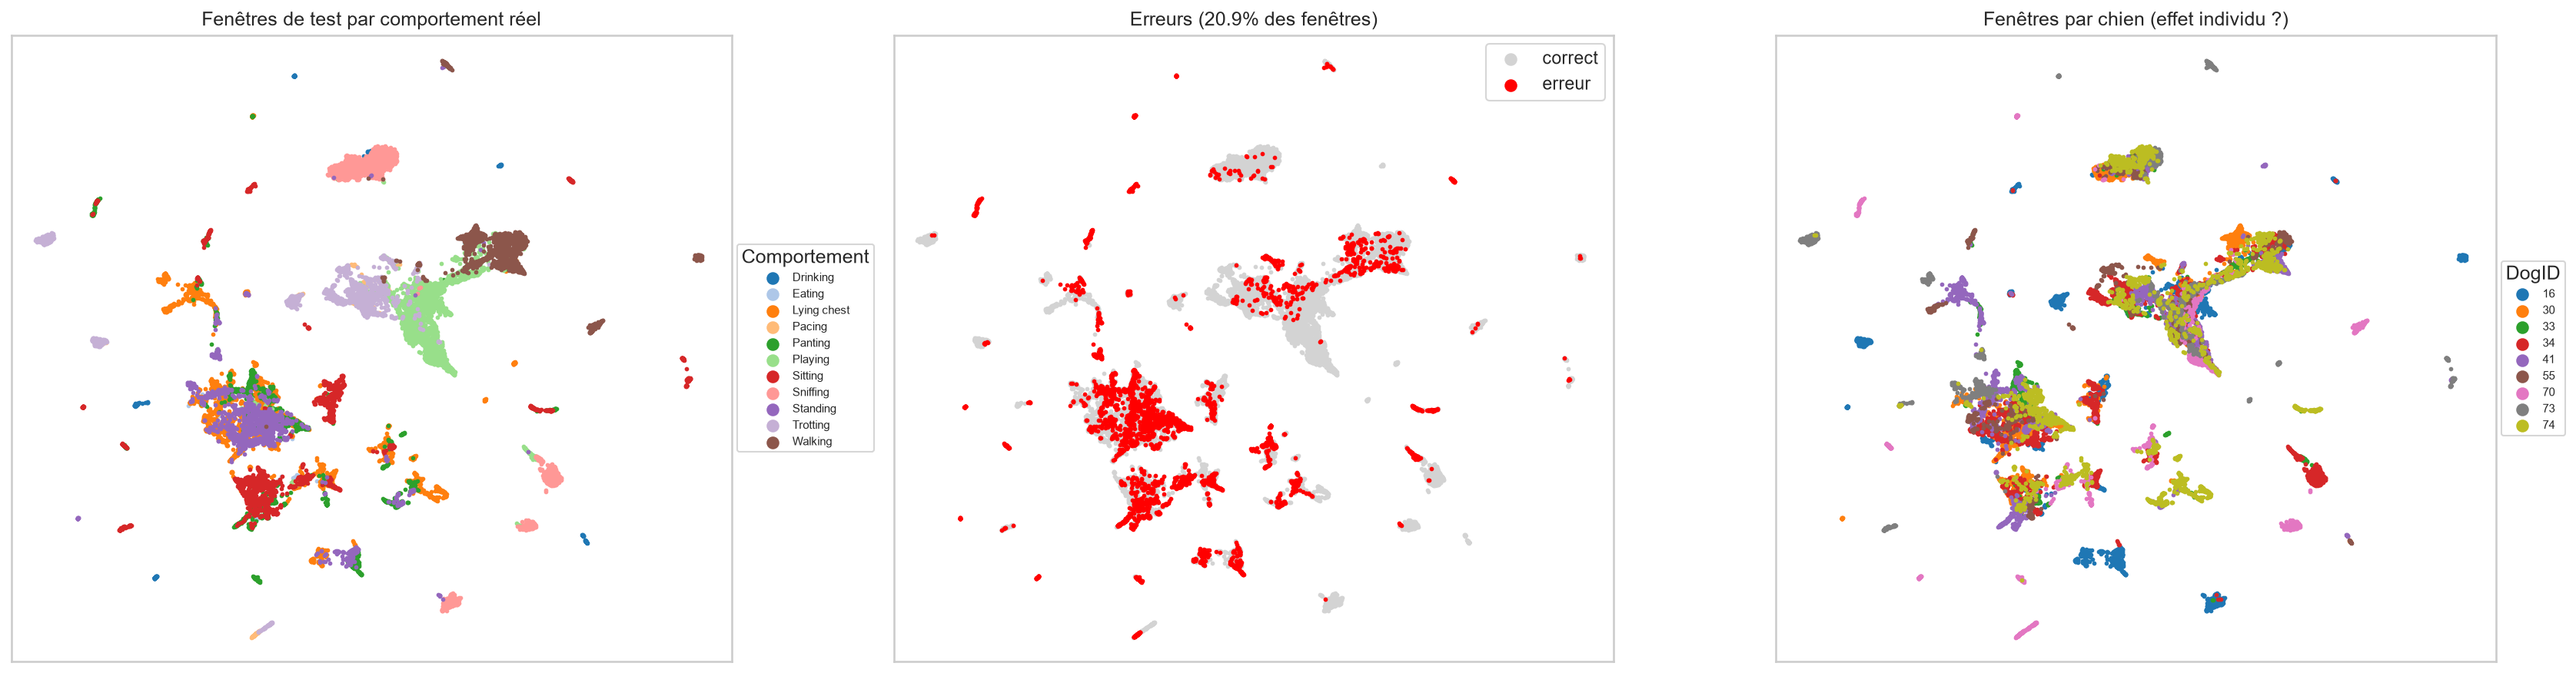

In [22]:
P.figure("07_umap_erreurs", width=1100)

- **comportements dynamiques** (marche, trot, jeu, flairage) : nuages où les chiens se mélangent, erreurs aux
  frontières entre classes voisines (Pacing et Trotting superposés) ;
- **comportements statiques** (couché, assis, debout, halètement) : un grand nuage mélangé qui concentre la
  majorité des erreurs (confirme le caractère non exclusif des labels) ;
- **effet individu** : de nombreux petits îlots ne contiennent qu'**un chien et un comportement**, souvent
  entièrement en erreur. Quand un chien réalise un comportement à sa façon (ou porte son collier autrement),
  le modèle se trompe en bloc.

### 7.3 Prédiction conforme : quantifier l'incertitude
Au lieu d'un comportement, le modèle renvoie un **ensemble** construit pour contenir le vrai comportement dans
au moins 90 % des cas (α = 0,10). Méthode **LAC** : sur des chiens de **calibration** (9 chiens du train,
modèle réentraîné sur les 27 autres), on prend le quantile à 90 % de « 1 - probabilité de la vraie classe » ;
une classe entre dans l'ensemble si sa probabilité dépasse le seuil correspondant. Implémentation maison
vérifiée avec la bibliothèque **MAPIE**, qui fournit aussi la méthode **APS** (ensembles adaptés à la
difficulté de chaque fenêtre).

,couverture,taille moyenne,part de singletons
LAC (maison),0.898,1.369,0.700
LAC (MAPIE),0.898,1.369,0.700
APS (MAPIE),0.929,1.557,0.602


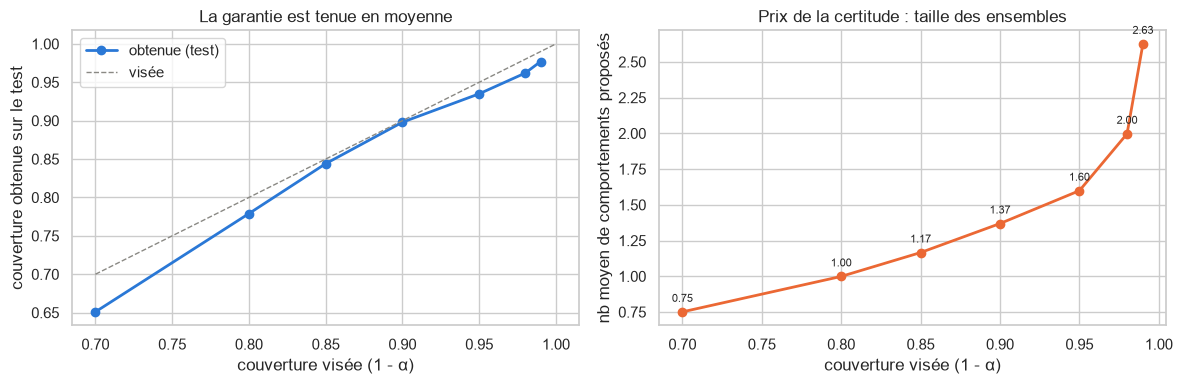

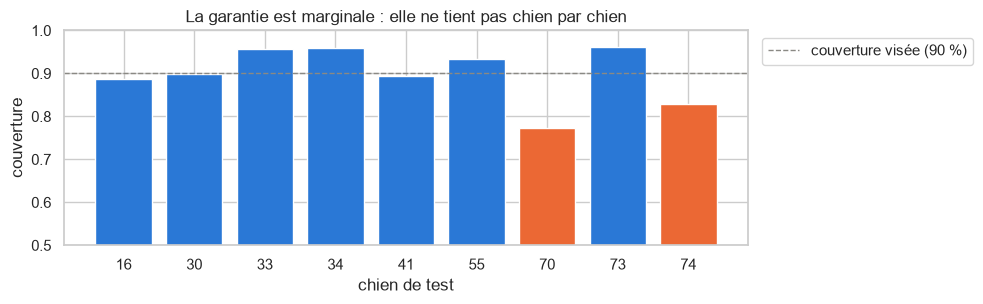

In [23]:
# Résultats relevés dans la sortie du notebook 07 (le modèle conforme demande un réentraînement)
conf_global = pd.DataFrame({"couverture": [0.898, 0.898, 0.929], "taille moyenne": [1.369, 1.369, 1.557],
                            "part de singletons": [0.700, 0.700, 0.602]},
                           index=["LAC (maison)", "LAC (MAPIE)", "APS (MAPIE)"])
display(conf_global.style.format("{:.3f}").set_caption("α = 0,10 : couverture visée 90 %"))
courbe = pd.DataFrame({"couverture_visee": [0.99, 0.98, 0.95, 0.90, 0.85, 0.80, 0.70],
                       "couverture": [0.977, 0.962, 0.935, 0.898, 0.844, 0.779, 0.651],
                       "taille_moyenne": [2.626, 1.997, 1.599, 1.369, 1.166, 0.999, 0.751]})
P.plot_courbe_conforme(courbe); plt.show()
conf_chien = pd.DataFrame({"DogID": [16, 30, 33, 34, 41, 55, 70, 73, 74],
                           "couverture": [0.886, 0.898, 0.957, 0.960, 0.895, 0.934, 0.773, 0.962, 0.829]})
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(conf_chien["DogID"].astype(str), conf_chien["couverture"],
       color=[P.ORANGE if c < 0.85 else P.BLEU for c in conf_chien["couverture"]])
ax.axhline(0.9, color=P.GRIS, ls="--", lw=1, label="couverture visée (90 %)")
ax.set_ylim(0.5, 1); ax.set_xlabel("chien de test"); ax.set_ylabel("couverture")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("La garantie est marginale : elle ne tient pas chien par chien")
plt.tight_layout(); plt.show()

- **garantie tenue en moyenne** (89,8 % pour 90 % visés), légère sous-couverture aux niveaux élevés : les
  chiens de calibration ne ressemblent pas parfaitement aux chiens de test (hypothèse d'échangeabilité) ;
- **70 % des fenêtres reçoivent un seul comportement** ; les autres, deux ou trois. En ajoutant en moyenne
  **0,37 comportement**, on passe de 79 % (exactitude) à 90 % de couverture : quand le modèle se trompe, la
  bonne réponse est très souvent sa deuxième proposition ;
- **le chien 70** (couverture 77 %) est aussi celui qui gagne le moins au lissage et qui apparaît en blocs
  d'erreurs dans la projection UMAP : trois analyses indépendantes pointent **la variabilité individuelle**.

---
## 8. Synthèse

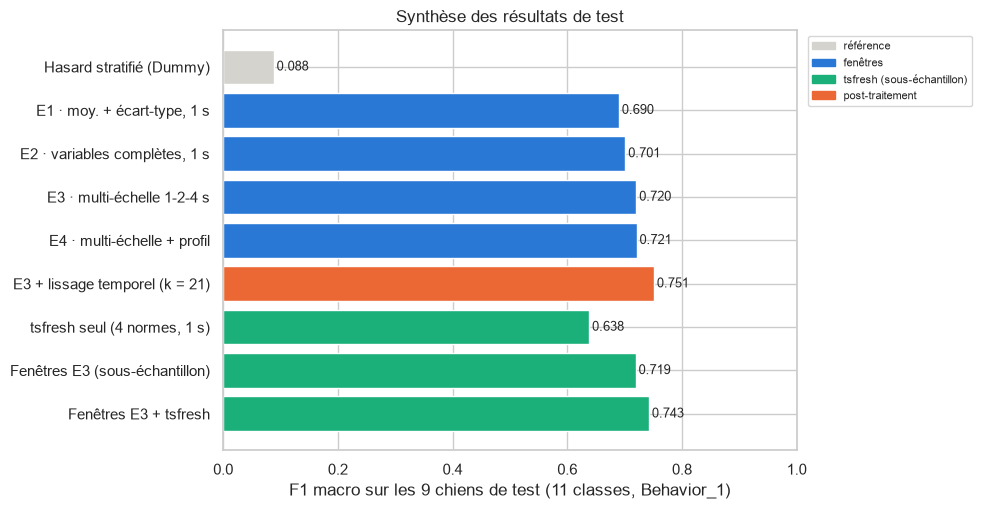

In [24]:
t04 = P.table("04_resultats_test_general")
t06 = P.table("06_resultats_test_tsfresh")
lignes = [("Hasard stratifié (Dummy)", t04.query("modele == 'Dummy_stratifie'")["f1_macro"].iloc[0], "référence")]
lignes += [(P.NOMS_EXPERIENCES[e], t04.loc[t04["experience"] == e, "f1_macro"].iloc[0], "fenêtres") for e in P.NOMS_EXPERIENCES]
lignes += [(f"E3 + lissage temporel (k = {K_LISSAGE})", apres["f1_macro"], "post-traitement")]
lignes += [(P.NOMS_TSFRESH[e], t06.loc[t06["experience"] == e, "f1_macro"].iloc[0], "tsfresh (sous-échantillon)")
           for e in ["tsfresh_1s", "approche1_sous_echantillon", "approche1+tsfresh"]]
P.plot_synthese(pd.DataFrame(lignes, columns=["approche", "f1_macro", "groupe"])); plt.show()

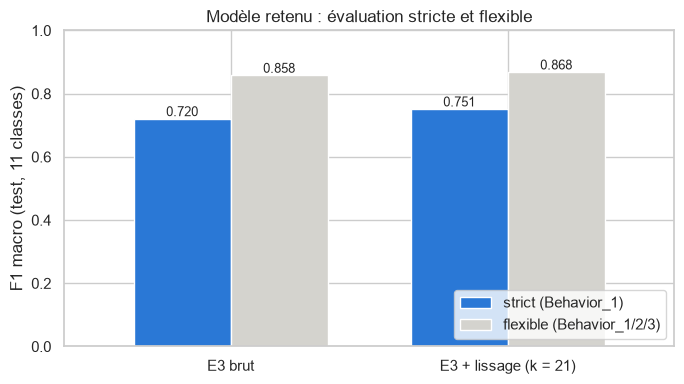

In [25]:
def f1_flexible(df, col):
    """F1 macro où une prédiction présente dans Behavior_1/2/3 est jugée correcte."""
    ok = evaluation.flexible_correct(df, col)
    verite = df["target"].where(~ok, df[col])
    return f1_score(verite, df[col], labels=classes, average="macro", zero_division=0)

flex = pd.DataFrame({
    "strict (Behavior_1)": [f1_score(preds["target"], preds[c], labels=classes, average="macro") for c in ("pred", "pred_lisse")],
    "flexible (Behavior_1/2/3)": [f1_flexible(preds, c) for c in ("pred", "pred_lisse")]},
    index=["E3 brut", f"E3 + lissage (k = {K_LISSAGE})"])

ax = flex.plot.bar(color=[P.BLEU, P.GRIS_CLAIR], figsize=(7, 4), rot=0, width=0.7)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=9)
ax.set_ylim(0, 1); ax.set_ylabel("F1 macro (test, 11 classes)")
ax.set_title("Modèle retenu : évaluation stricte et flexible")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

| Ce qui marche | Ce qui limite |
|---|---|
| Variables physiques simples + **contexte multi-échelle** (F1 0,72 sur des chiens jamais vus) | **Variabilité entre chiens** : F1 de 0,52 à 0,76 selon le chien, effet visible dans les trois analyses complémentaires |
| **Lissage temporel** : +0,03 pour un coût nul | **Labels non exclusifs** : plus de la moitié des erreurs strictes désignent un comportement en cours |
| Locomotion et flairage reconnus à plus de 95 % | Postures statiques et halètement confondus (lié au multi label) |
| Protocole honnête : split et CV par chien, choix sur la CV, test utilisé une fois | Un seul split, 9 chiens de test |

---
## 9. Discussion (questions anticipées)

**Behavior_2 et Behavior_3 améliorent-ils les performances ?** Ils améliorent le **score mesuré** (évaluation
flexible, 0,792 → 0,903), pas le modèle lui-même : ils montrent que beaucoup d'« erreurs » sont des
comportements simultanés. Ils servent aussi à l'**entraînement** des modèles spécifiques (plus d'exemples de
posture et d'activité, environ 30 % de couverture en plus).

**Y a-t-il du surapprentissage ?**

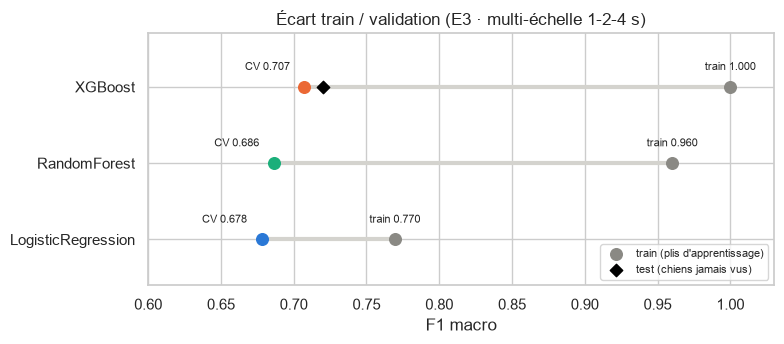

,train E3,CV E3,train E4 (+ profil),CV E4 (+ profil)
modele,,,,
XGBoost,1.00,0.707,0.995,0.688
RandomForest,0.96,0.686,0.982,0.675
LogisticRegression,0.77,0.678,0.777,0.668


In [26]:
P.plot_surapprentissage(cv04, f1_test={"XGBoost": avant["f1_macro"]}); plt.show()
e3 = cv04[cv04["experience"] == "multi_echelle"].set_index("modele")
e4 = cv04[cv04["experience"] == "multi_echelle+profil"].set_index("modele")
display(pd.DataFrame({"train E3": e3["f1_macro_train_moy"], "CV E3": e3["f1_macro_cv_moy"],
                      "train E4 (+ profil)": e4["f1_macro_train_moy"], "CV E4 (+ profil)": e4["f1_macro_cv_moy"]})
        .drop(index=list(modeling.DUMMY_MODELS)).round(3))

- XGBoost atteint F1 = 1,000 sur ses plis d'apprentissage contre 0,707 en validation : il mémorise le train,
  ce qui est habituel pour le boosting et les forêts. **Ce qui compte**, c'est que le choix se fait sur la CV, et le
  score de test (0,720) est conforme à la CV. L'écart train / CV mesure surtout la **difficulté de généraliser
  à de nouveaux chiens**.
- Pistes non explorées : régularisation plus forte de XGBoost (`min_child_weight`, `subsample`, arrêt précoce).

**Les variables de profil sont-elles retenues par la sélection ?**

In [27]:
b_e4 = modeling.load_bundle("general", "multi_echelle+profil", "XGBoost")
ret_e4 = modeling.selected_features(b_e4["model"], b_e4["features"])
imp_e4 = pd.Series(b_e4["model"].named_steps["clf"].feature_importances_, index=ret_e4).rank(ascending=False).astype(int)
print(f"E4 : {len(ret_e4)} variables retenues sur {len(b_e4['features'])}")
for v in cfg.STATIC_FEATURES:
    print(f"  {v:<16}: " + (f"retenue, rang d'importance {imp_e4[v]} / {len(ret_e4)}" if v in imp_e4 else "non retenue"))

E4 : 93 variables retenues sur 286
  Weight          : retenue, rang d'importance 52 / 93
  Age months      : retenue, rang d'importance 69 / 93
  Gender          : non retenue
  NeuteringStatus : non retenue


Dans E4, la sélection retient le poids et l'âge (rangs d'importance 52 et 69 sur 93 dans le modèle
final : un rôle modéré), mais écarte le genre et le statut de stérilisation. Ce n'est pas un hasard :
poids et âge prennent presque une valeur différente par chien (21 poids et 38 âges distincts pour
45 chiens), ils permettent donc pratiquement d'**identifier** un chien, alors que les variables
binaires ne le peuvent pas.

Avec le profil, le score d'apprentissage reste stable ou augmente et le score de validation diminue
(XGBoost : 0,707 → 0,688 en CV). Interprétation probable : constantes pour un chien, ces variables
aident le modèle à reconnaître les chiens d'apprentissage plutôt qu'à généraliser à de nouveaux chiens.

**La sélection de variables par forêt rapide : pourquoi, et qu'apporte-t-elle ?**

In [28]:
retenues = modeling.selected_features(general["model"], general["features"])
blocs = P.selection_par_bloc(general["features"], retenues)
print(f"Modèle retenu : {len(retenues)} variables gardées sur {len(general['features'])}")
display(blocs["échelle"].T, blocs["capteur"].T)

Modèle retenu : 91 variables gardées sur 282


échelle,w1s,w2s,w4s
retenues,29.00,32.00,30.00
total,94.00,94.00,94.00
part,0.31,0.34,0.32


capteur,ABack,ANeck,GBack,GNeck,ratio
retenues,43.00,23.00,16.00,9.00,0.0
total,69.00,69.00,69.00,69.00,6.0
part,0.62,0.33,0.23,0.13,0.0


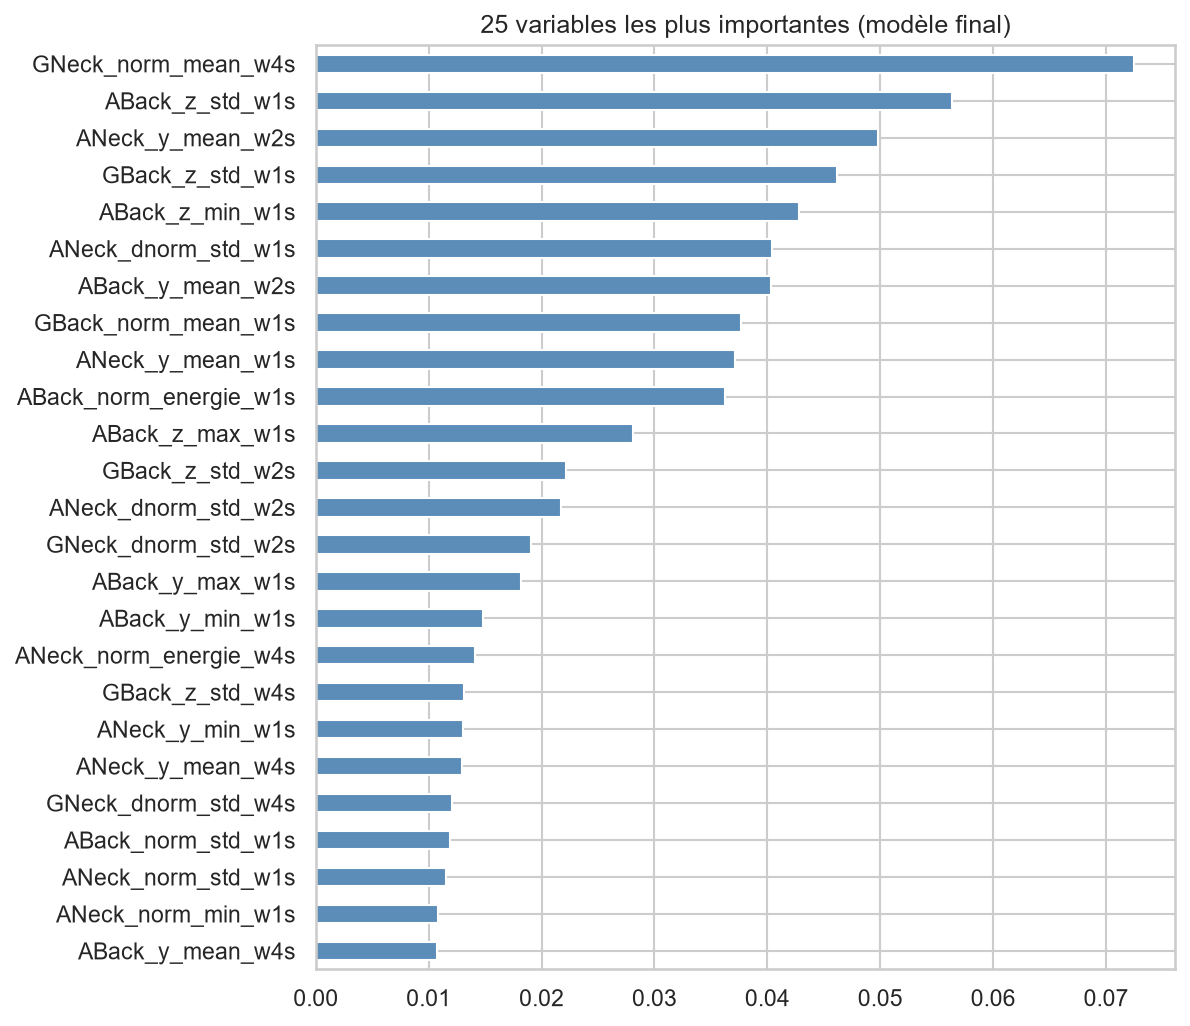

In [29]:
P.figure("04_importances", width=600)

- **Pourquoi** : 282 variables très corrélées (mêmes signaux à trois échelles). Une forêt de 50 arbres classe
  leur importance en quelques secondes et on garde celles au-dessus de la moyenne. C'est **peu coûteux**,
  placé **dans le pipeline** (ajusté sur chaque pli : pas de fuite) et mis en cache (calculé une fois par pli,
  pas une fois par point de la grille).
- **Apports** : environ trois fois moins de variables pour le classifieur (temps d'entraînement), moins de
  bruit pour la régression logistique, et une **liste interprétable** : intensité de rotation du cou sur 4 s,
  orientation du cou et du dos (moyennes des axes y), variabilité des mouvements du dos ; les trois échelles
  sont représentées.
- Je n'ai pas fait d'expérience sans sélection ; son effet sur le score n'est pas mesuré
  isolément. Le seuil (la moyenne) n'est pas non plus optimisé.

**Pourquoi pas d'AUC ?**

In [30]:
auc_cl = {c: roc_auc_score(preds["target"] == c, proba[:, i]) for i, c in enumerate(classes)
          if preds["target"].eq(c).any()}          # AUC « un contre tous », classe par classe
auc = np.mean(list(auc_cl.values()))
print(f"AUC ROC macro (un contre tous) du modèle retenu sur le test : {auc:.3f}")
print("Par classe :", {c: round(v, 3) for c, v in sorted(auc_cl.items(), key=lambda kv: kv[1])})

AUC ROC macro (un contre tous) du modèle retenu sur le test : 0.976
Par classe : {'Panting': 0.922, 'Lying chest': 0.948, 'Eating': 0.95, 'Standing': 0.961, 'Sitting': 0.979, 'Playing': 0.989, 'Pacing': 0.992, 'Walking': 0.998, 'Trotting': 0.999, 'Drinking': 0.999, 'Sniffing': 1.0}


- L'AUC mesure la qualité du **classement** des probabilités, indépendamment de tout seuil. Notre décision est
  l'argmax et nos classes sont déséquilibrées : le **F1 macro** mesure directement la qualité de cette
  décision, classe par classe. En multiclasse, l'AUC « un contre tous » est aussi optimiste quand une classe est
  rare (beaucoup de vrais négatifs faciles).
- Elle se calcule en une ligne à partir des probabilités enregistrées (ci-dessus) : on peut vérifier que les
  classes les plus difficiles sont les mêmes qu'avec le F1.
- Panting (0,922), Lying chest, Eating et Standing ont les AUC les plus faibles, ce sont aussi les classes difficiles en F1. Et Eating obtient 0,95 d’AUC pour seulement 0,255 de F1 : c’est exactement l’exemple d’AUC trop indulgente pour une classe rare.

**Valeurs de Shapley pour expliquer une prédiction individuelle ?**
Avec XGBoost, les valeurs de Shapley exactes se calculent rapidement (`shap.TreeExplainer`) : pour une fenêtre
donnée, on verrait quelles variables poussent vers « Panting » plutôt que « Standing ».

Fenêtre 2458 : vrai = Panting, prédit = Standing


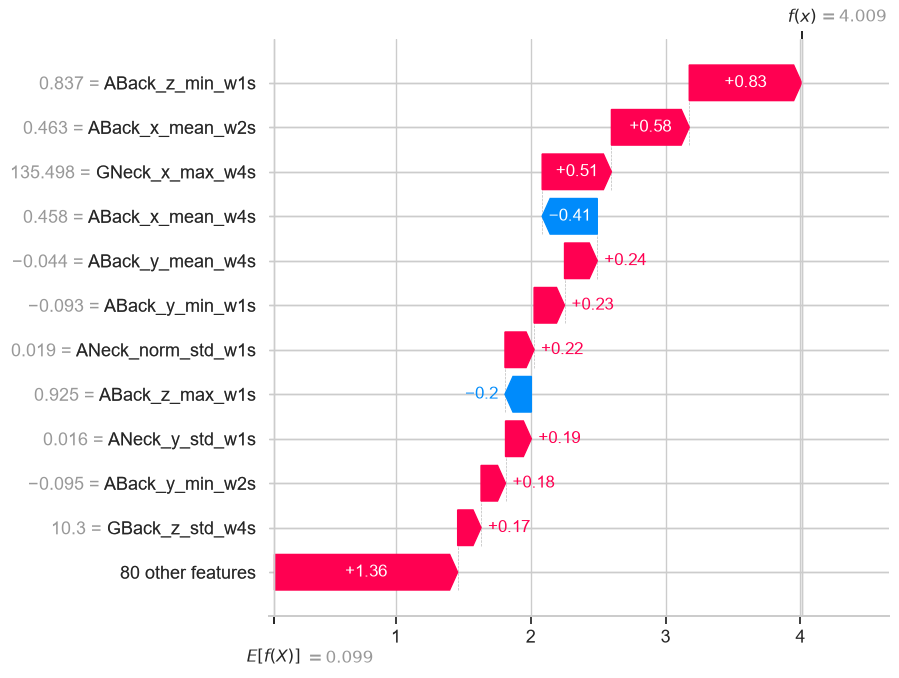

DogID               16
TestNum              1
t_center        1231.0
behavior_1     Panting
behavior_2    Standing
behavior_3         NaN
pred          Standing
proba_Standing    0.961
proba_Panting     0.038
proba_Eating      0.000


In [31]:
EXPLIQUER = True   # passer à True pour la démonstration (pip install shap)
if EXPLIQUER:
    import shap
    sel, clf = general["model"].named_steps["selecteur"], general["model"].named_steps["clf"]
    fen = fen_test.set_index("window_id").loc[preds["window_id"]]
    i = int(np.flatnonzero((preds["target"] == "Panting") & (preds["pred"] != "Panting"))[0])   # une erreur typique
    x = pd.DataFrame(sel.transform(fen[general["features"]].iloc[[i]]), columns=retenues)
    k = classes.index(preds["pred"].iloc[i])
    expl = shap.TreeExplainer(clf)(x)
    print(f"Fenêtre {preds['window_id'].iloc[i]} : vrai = Panting, prédit = {classes[k]}")
    shap.plots.waterfall(expl[0, :, k], max_display=12)

r = preds.iloc[i]
print(r[["DogID", "TestNum", "t_center", "behavior_1", "behavior_2", "behavior_3", "pred"]].to_string())
print(r[[f"proba_{c}" for c in classes]].astype(float).sort_values(ascending=False).head(3).round(3).to_string())

---
## 10. Ouverture

**Impact du split train / test.** Un seul split, 9 chiens : le score de test dépend du tirage (Sitting
surreprésenté, Eating sous-représenté dans le test). La dispersion par chien (0,632 ± 0,074) en donne l'ordre
de grandeur. Mesure plus fiable : répéter le split avec plusieurs graines (fonction
`modeling.split_sensitivity`, non faite faute de temps) ou faire une validation
**« un chien laissé de côté »** sur les 45 chiens.

**Le deep learning est-il pertinent pour la suite ?**
- *Oui...* : un modèle profond peut apprendre lui-même ses variables à partir
  des signaux bruts et de plusieurs échelles ; une sortie **multi-label** pourra traiter
  naturellement les comportements simultanés ; des **augmentations** (rotations des axes) peuvent simuler un
  collier placé différemment, donc cibler directement l'effet individu.
- *...mais attention* : seulement 45 chiens, alors que la principale source d'erreur est la variabilité entre chiens ;
  coût de calcul et de réglage, moindre interprétabilité. Le gain n'est pas garanti face à 0,72 / 0,75, et il
  faudrait le même protocole (validation par chien) pour le démontrer.

**tsfresh avec toute l'information.** Lui donner aussi les 12 axes bruts multiplierait le temps d'extraction
par 4 mais pourrait permettre d'améliorer les résultats en découvrant de nouvelles features déterminantes.